# TP4 – Analyse des données Retail Intelligence (UC-08)

Objectif : calculer des KPI du dictionnaire du Jour 1, produire des statistiques descriptives, deux analyses métier et des graphiques, à partir des jeux **Silver et Gold produits au Jour 3**. Les calculs sont faits avec PySpark ; seuls de petits tableaux agrégés passent dans pandas pour Matplotlib.

Les tables de ventes ne sont pas dans le kit reçu : seuls KPI-08, KPI-09 et KPI-10 sont calculables. Les données sont synthétiques.

## 1. Environnement et session Spark

In [1]:
import os, platform, subprocess
import pyspark, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from pyspark.sql import SparkSession, functions as F

DATA = os.environ.get('DATA_DIR', '/j3/data')
OUT, VIS = Path('../preuves/uc08/resultats'), Path('../visualisations')
OUT.mkdir(parents=True, exist_ok=True); VIS.mkdir(exist_ok=True)

print('Python :', platform.python_version())
print('PySpark :', pyspark.__version__)
print('pandas :', pd.__version__)
print('Matplotlib :', matplotlib.__version__)
print(subprocess.run(['java', '-version'], capture_output=True, text=True).stderr.splitlines()[0])
spark = (SparkSession.builder.appName('TP4-Retail-Intelligence').master('local[4]')
         .config('spark.driver.memory', '4g').config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.showConsoleProgress', 'false').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print('Spark :', spark.version, '| mode :', spark.sparkContext.master)
print('Données lues dans :', DATA)

Python : 3.12.14
PySpark : 4.3.0
pandas : 2.3.3
Matplotlib : 3.11.2
openjdk version "21.0.13" 2026-10-20


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/19 14:20:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark : 4.3.0 | mode : local[4]
Données lues dans : /j3/data


## 2. Chargement et inventaire des jeux utilisés

Schéma, volume et granularité de chaque jeu avant tout calcul.

In [2]:
jeux = {
    ('silver', 'clients_enrichis'): 'un client',
    ('silver', 'inventory'): 'une date, un article, un entrepôt',
    ('silver', 'date_dim'): 'un jour',
    ('gold', 'clients_par_etat'): 'un état',
    ('gold', 'clients_par_tranche_revenu'): 'une tranche de revenu',
    ('gold', 'stock_moyen_entrepot_mois'): 'un entrepôt et un mois',
}
df = {}
inventaire = []
for (zone, nom), grain in jeux.items():
    d = spark.read.parquet(f'{DATA}/{zone}/{nom}')
    df[nom] = d
    inventaire.append({'jeu': nom, 'zone': zone, 'format': 'Parquet', 'granularite': grain, 'lignes': d.count(), 'colonnes': len(d.columns)})
    print('=====', zone, '/', nom, '=====')
    d.printSchema()
pd.DataFrame(inventaire).to_csv(OUT / 'inventaire_jeux.csv', index=False)
pd.DataFrame(inventaire)

===== silver / clients_enrichis =====
root
 |-- c_customer_sk: long (nullable = true)
 |-- c_customer_id: string (nullable = true)
 |-- c_current_cdemo_sk: long (nullable = true)
 |-- c_current_hdemo_sk: long (nullable = true)
 |-- c_current_addr_sk: long (nullable = true)
 |-- c_first_shipto_date_sk: long (nullable = true)
 |-- c_first_sales_date_sk: long (nullable = true)
 |-- c_salutation: string (nullable = true)
 |-- c_preferred_cust_flag: string (nullable = true)
 |-- c_birth_year: integer (nullable = true)
 |-- c_birth_country: string (nullable = true)
 |-- c_last_review_date: string (nullable = true)
 |-- email_domaine: string (nullable = true)
 |-- _source: string (nullable = true)
 |-- _traite_le: timestamp (nullable = true)
 |-- ca_city: string (nullable = true)
 |-- ca_county: string (nullable = true)
 |-- ca_state: string (nullable = true)
 |-- ca_zip: string (nullable = true)
 |-- ca_country: string (nullable = true)
 |-- hd_income_band_sk: long (nullable = true)
 |-- hd_

===== silver / inventory =====
root
 |-- inv_date_sk: long (nullable = true)
 |-- inv_item_sk: long (nullable = true)
 |-- inv_warehouse_sk: long (nullable = true)
 |-- inv_quantity_on_hand: integer (nullable = true)
 |-- date_complete: boolean (nullable = true)
 |-- _source: string (nullable = true)
 |-- _traite_le: timestamp (nullable = true)



===== silver / date_dim =====
root
 |-- d_date_sk: long (nullable = true)
 |-- d_date_id: string (nullable = true)
 |-- d_date: date (nullable = true)
 |-- d_month_seq: integer (nullable = true)
 |-- d_week_seq: integer (nullable = true)
 |-- d_quarter_seq: integer (nullable = true)
 |-- d_year: integer (nullable = true)
 |-- d_dow: integer (nullable = true)
 |-- d_moy: integer (nullable = true)
 |-- d_dom: integer (nullable = true)
 |-- d_qoy: integer (nullable = true)
 |-- d_fy_year: integer (nullable = true)
 |-- d_fy_quarter_seq: integer (nullable = true)
 |-- d_fy_week_seq: integer (nullable = true)
 |-- d_day_name: string (nullable = true)
 |-- d_quarter_name: string (nullable = true)
 |-- d_holiday: string (nullable = true)
 |-- d_weekend: string (nullable = true)
 |-- d_following_holiday: string (nullable = true)
 |-- d_first_dom: integer (nullable = true)
 |-- d_last_dom: integer (nullable = true)
 |-- d_same_day_ly: integer (nullable = true)
 |-- d_same_day_lq: integer (nulla

===== gold / clients_par_etat =====
root
 |-- etat: string (nullable = true)
 |-- nb_clients: long (nullable = true)
 |-- part_pct: double (nullable = true)



===== gold / clients_par_tranche_revenu =====
root
 |-- hd_income_band_sk: long (nullable = true)
 |-- tranche: string (nullable = true)
 |-- nb_clients: long (nullable = true)
 |-- part_pct: double (nullable = true)



===== gold / stock_moyen_entrepot_mois =====
root
 |-- inv_warehouse_sk: long (nullable = true)
 |-- d_year: integer (nullable = true)
 |-- d_moy: integer (nullable = true)
 |-- stock_moyen: double (nullable = true)
 |-- nb_dates: long (nullable = true)
 |-- nb_lignes: long (nullable = true)
 |-- nb_quantites_nulles: long (nullable = true)



,jeu,zone,format,granularite,lignes,colonnes
0,clients_enrichis,silver,Parquet,un client,99000,25
1,inventory,silver,Parquet,"une date, un article, un entrepôt",21791808,7
2,date_dim,silver,Parquet,un jour,109573,30
3,clients_par_etat,gold,Parquet,un état,52,3
4,clients_par_tranche_revenu,gold,Parquet,une tranche de revenu,21,4
5,stock_moyen_entrepot_mois,gold,Parquet,un entrepôt et un mois,280,7


## 3. Vérification de la granularité et de la cohérence

Une ligne par client, un état par ligne, un entrepôt et un mois par ligne ; les totaux du Gold doivent retrouver ceux du Silver.

In [3]:
clients, inv, dates = df['clients_enrichis'], df['inventory'], df['date_dim']
g_etat, g_tranche, g_stock = df['clients_par_etat'], df['clients_par_tranche_revenu'], df['stock_moyen_entrepot_mois']

n_clients = clients.count()
controles = [
    ('clients_enrichis : c_customer_sk unique', n_clients == clients.select('c_customer_sk').distinct().count()),
    ('clients_par_etat : un état par ligne', g_etat.count() == g_etat.select('etat').distinct().count()),
    ('clients_par_etat : somme = nb de clients', g_etat.agg(F.sum('nb_clients')).first()[0] == n_clients),
    ('clients_par_tranche_revenu : somme = nb de clients', g_tranche.agg(F.sum('nb_clients')).first()[0] == n_clients),
    ('stock_moyen_entrepot_mois : un entrepôt et un mois par ligne', g_stock.count() == g_stock.select('inv_warehouse_sk', 'd_year', 'd_moy').distinct().count()),
]
for texte, ok in controles:
    print('OK ' if ok else 'ECHEC', texte)
assert all(ok for _, ok in controles)

OK  clients_enrichis : c_customer_sk unique
OK  clients_par_etat : un état par ligne
OK  clients_par_etat : somme = nb de clients
OK  clients_par_tranche_revenu : somme = nb de clients
OK  stock_moyen_entrepot_mois : un entrepôt et un mois par ligne


## 4. KPI calculés

Définitions : dictionnaire des KPI du Jour 1 (voir `docs`/rapport). **KPI-09** nombre de clients, **KPI-10** répartition par tranche de revenu du foyer, **KPI-08** stock moyen par entrepôt.

In [4]:
# KPI-09 : nombre de clients (distincts) et clients sans adresse
kpi09 = clients.select(F.countDistinct('c_customer_sk')).first()[0]
sans_adresse = clients.filter(F.col('ca_state').isNull()).count()
print('KPI-09 clients :', kpi09, '| sans adresse :', sans_adresse)

# KPI-10 : tranche la plus et la moins peuplée (hors non renseigné)
t = g_tranche.filter(F.col('hd_income_band_sk').isNotNull()).toPandas()
haut, bas = t.loc[t['nb_clients'].idxmax()], t.loc[t['nb_clients'].idxmin()]
print('KPI-10 tranche la plus peuplée :', haut['tranche'], haut['nb_clients'], '| la moins peuplée :', bas['tranche'], bas['nb_clients'])

# KPI-08 : stock moyen = moyenne de inv_quantity_on_hand (lignes non nulles, dates complètes), recalculé depuis le Silver
inv_ok = inv.filter(F.col('date_complete'))
stock_global = inv_ok.agg(F.avg('inv_quantity_on_hand')).first()[0]
stock_ent = inv_ok.groupBy('inv_warehouse_sk').agg(F.avg('inv_quantity_on_hand').alias('stock_moyen')).orderBy('inv_warehouse_sk').toPandas()
print('KPI-08 stock moyen global :', round(stock_global, 2))
print(stock_ent)

# contrôle croisé : moyenne pondérée du Gold = valeur recalculée depuis le Silver
g = g_stock.agg((F.sum(F.col('stock_moyen') * (F.col('nb_lignes') - F.col('nb_quantites_nulles'))) / F.sum(F.col('nb_lignes') - F.col('nb_quantites_nulles'))).alias('m')).first()['m']
print('Moyenne pondérée du Gold :', round(g, 2), '| écart avec le Silver :', round(abs(g - stock_global), 4))

kpi = pd.DataFrame([
    ['KPI-09', 'Nombre de clients', kpi09, 'clients', 'global, clients_enrichis (Silver)'],
    ['KPI-09', 'Clients sans adresse', sans_adresse, 'clients', 'ca_state vide'],
    ['KPI-10', 'Tranche de revenu la plus peuplée : ' + haut['tranche'], int(haut['nb_clients']), 'clients', '20 tranches, hors non renseigné'],
    ['KPI-10', 'Tranche de revenu la moins peuplée : ' + bas['tranche'], int(bas['nb_clients']), 'clients', '20 tranches, hors non renseigné'],
    ['KPI-08', 'Stock moyen (tous entrepôts)', round(stock_global, 2), 'unités', 'inventory Silver, dates complètes'],
] + [['KPI-08', f'Stock moyen entrepôt {int(r.inv_warehouse_sk)}', round(r.stock_moyen, 2), 'unités', 'inventory Silver, dates complètes'] for r in stock_ent.itertuples()],
    columns=['kpi', 'nom', 'valeur', 'unite', 'perimetre'], dtype=object)
kpi.to_csv(OUT / 'kpi.csv', index=False)
kpi

KPI-09 clients : 99000 | sans adresse : 22


KPI-10 tranche la plus peuplée : 130001-140000 5447 | la moins peuplée : 90001-100000 4660


KPI-08 stock moyen global : 500.16
   inv_warehouse_sk  stock_moyen
0                 0   500.308527
1                 1   500.209679
2                 2   500.081643
3                 3   499.919108
4                 4   500.304368


Moyenne pondérée du Gold : 500.16 | écart avec le Silver : 0.0003


,kpi,nom,valeur,unite,perimetre
0,KPI-09,Nombre de clients,99000,clients,"global, clients_enrichis (Silver)"
1,KPI-09,Clients sans adresse,22,clients,ca_state vide
2,KPI-10,Tranche de revenu la plus peuplée : 130001-140000,5447,clients,"20 tranches, hors non renseigné"
3,KPI-10,Tranche de revenu la moins peuplée : 90001-100000,4660,clients,"20 tranches, hors non renseigné"
4,KPI-08,Stock moyen (tous entrepôts),500.16,unités,"inventory Silver, dates complètes"
5,KPI-08,Stock moyen entrepôt 0,500.31,unités,"inventory Silver, dates complètes"
6,KPI-08,Stock moyen entrepôt 1,500.21,unités,"inventory Silver, dates complètes"
7,KPI-08,Stock moyen entrepôt 2,500.08,unités,"inventory Silver, dates complètes"
8,KPI-08,Stock moyen entrepôt 3,499.92,unités,"inventory Silver, dates complètes"
9,KPI-08,Stock moyen entrepôt 4,500.3,unités,"inventory Silver, dates complètes"


## 5. Statistiques descriptives

Mesures numériques : année de naissance, nombre de personnes à charge et de véhicules du foyer (clients), quantité en stock (inventory). Compteurs et sommes via Spark ; médiane approchée (`percentile_approx`).

In [5]:
def stats(d, colonnes, jeu):
    lignes = []
    for c in colonnes:
        r = d.agg(F.count(c).alias('n'), F.sum(F.col(c).isNull().cast('int')).alias('nuls'), F.min(c).alias('min'), F.max(c).alias('max'),
                  F.avg(c).alias('moyenne'), F.percentile_approx(c, 0.5).alias('mediane'), F.stddev(c).alias('ecart_type')).first()
        lignes.append({'jeu': jeu, 'colonne': c, 'valeurs': r['n'], 'manquantes': r['nuls'], 'min': r['min'], 'max': r['max'],
                       'moyenne': round(r['moyenne'], 2), 'mediane': r['mediane'], 'ecart_type': round(r['ecart_type'], 2)})
    return lignes

st = stats(clients, ['c_birth_year', 'hd_dep_count', 'hd_vehicle_count'], 'clients_enrichis') + stats(inv_ok, ['inv_quantity_on_hand'], 'inventory (dates complètes)')
pdf_stats = pd.DataFrame(st)
pdf_stats.to_csv(OUT / 'statistiques.csv', index=False)
pdf_stats

,jeu,colonne,valeurs,manquantes,min,max,moyenne,mediane,ecart_type
0,clients_enrichis,c_birth_year,98970,30,1924,1992,1958.05,1958,19.92
1,clients_enrichis,hd_dep_count,98937,63,0,9,2.43,1,2.41
2,clients_enrichis,hd_vehicle_count,94997,4003,0,4,1.82,2,1.13
3,inventory (dates complètes),inv_quantity_on_hand,21774389,5611,0,1000,500.16,500,288.97


In [6]:
# répartitions par catégorie (variables qualitatives des clients)
rep = []
for c in ['c_preferred_cust_flag', 'hd_buy_potential', 'c_salutation']:
    p = clients.groupBy(F.coalesce(F.col(c).cast('string'), F.lit('Non renseigné')).alias('valeur')).count().orderBy(F.desc('count')).toPandas()
    p.insert(0, 'colonne', c)
    p['part_pct'] = (100 * p['count'] / n_clients).round(2)
    rep.append(p)
repartitions = pd.concat(rep)
repartitions.rename(columns={'count': 'nb_clients'}).to_csv(OUT / 'repartitions.csv', index=False)
repartitions

,colonne,valeur,count,part_pct
0,c_preferred_cust_flag,N,49512,50.01
1,c_preferred_cust_flag,Y,49461,49.96
2,c_preferred_cust_flag,Non renseigné,27,0.03
0,hd_buy_potential,1001-5000,36171,36.54
1,hd_buy_potential,5001-10000,20905,21.12
2,hd_buy_potential,0-500,16865,17.04
3,hd_buy_potential,501-1000,16842,17.01
4,hd_buy_potential,>10000,4161,4.20
5,hd_buy_potential,Unknown,4009,4.05
6,hd_buy_potential,Non renseigné,47,0.05


## 6. Analyse 1 – Comment évolue le stock moyen dans le temps ? (KPI-08)

Source : `gold/stock_moyen_entrepot_mois` (5 entrepôts × 56 mois). Un point par entrepôt et par mois.

2001-01 -> 2005-08 | 56 mois | 5 entrepôts
                    min    max   mean
inv_warehouse_sk                     
0                 498.5  502.8  500.3
1                 498.4  502.4  500.2
2                 498.3  502.1  500.1
3                 498.2  502.3  499.9
4                 497.7  502.8  500.3


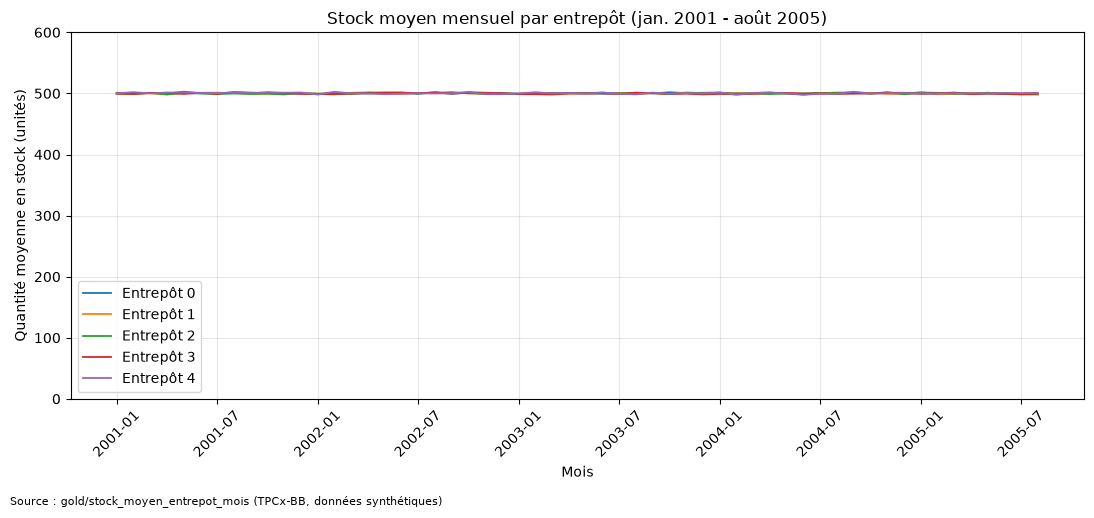

In [7]:
ts = g_stock.orderBy('d_year', 'd_moy').toPandas()
ts['mois'] = ts['d_year'].astype(str) + '-' + ts['d_moy'].astype(str).str.zfill(2)
print(ts['mois'].min(), '->', ts['mois'].max(), '|', ts['mois'].nunique(), 'mois |', ts['inv_warehouse_sk'].nunique(), 'entrepôts')
print(ts.groupby('inv_warehouse_sk')['stock_moyen'].agg(['min', 'max', 'mean']).round(1))
ts[['inv_warehouse_sk', 'mois', 'stock_moyen', 'nb_dates', 'nb_lignes']].to_csv(OUT / 'stock_moyen_mensuel.csv', index=False)

plt.figure(figsize=(11, 5))
for e, g in ts.groupby('inv_warehouse_sk'):
    plt.plot(g['mois'], g['stock_moyen'], label=f'Entrepôt {e}', linewidth=1.3)
plt.title('Stock moyen mensuel par entrepôt (jan. 2001 - août 2005)')
plt.xlabel('Mois')
plt.ylabel('Quantité moyenne en stock (unités)')
plt.xticks(range(0, ts['mois'].nunique(), 6), sorted(ts['mois'].unique())[::6], rotation=45)
plt.grid(True, alpha=0.3)
plt.ylim(0, 600)
plt.legend()
plt.figtext(0.01, -0.02, 'Source : gold/stock_moyen_entrepot_mois (TPCx-BB, données synthétiques)', fontsize=8)
plt.tight_layout()
plt.savefig(VIS / 'stock_moyen_mensuel.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Analyse 2 – Où sont les clients ? (KPI-09)

Source : `gold/clients_par_etat` (52 lignes dont « Non renseigné »). Graphique limité aux 10 premiers états (filtre documenté).

  etat  nb_clients  part_pct
0   TX        8189      8.27
1   GA        5081      5.13
2   VA        4394      4.44
3   KY        3848      3.89
4   KS        3379      3.41
5   MO        3287      3.32
6   IL        3200      3.23
7   IA        3133      3.16
8   TN        3118      3.15
9   IN        3057      3.09
Part des 10 premiers états : 41.09 % | nombre d états au total : 52
Etat le plus petit : {'etat': 'Non renseigne', 'nb_clients': 22, 'part_pct': 0.02}


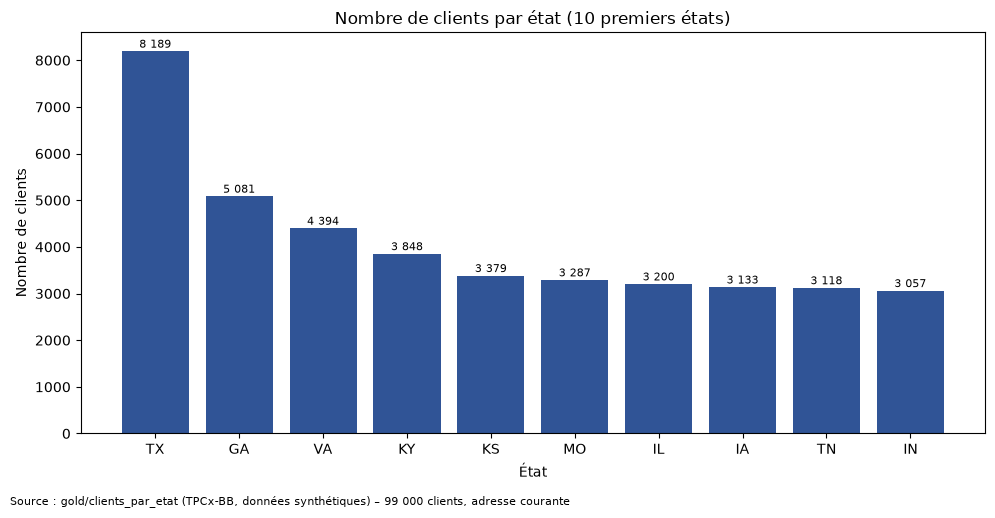

In [8]:
etat = g_etat.orderBy(F.desc('nb_clients')).toPandas()
top = etat.head(10)
print(top)
print('Part des 10 premiers états :', round(top['part_pct'].sum(), 2), '% | nombre d états au total :', len(etat))
print('Etat le plus petit :', etat.iloc[-1].to_dict())
etat.to_csv(OUT / 'clients_par_etat.csv', index=False)

plt.figure(figsize=(10, 5))
plt.bar(top['etat'], top['nb_clients'], color='#305496')
for i, v in enumerate(top['nb_clients']):
    plt.text(i, v + 80, f'{v:,}'.replace(',', ' '), ha='center', fontsize=8)
plt.title('Nombre de clients par état (10 premiers états)')
plt.xlabel('État')
plt.ylabel('Nombre de clients')
plt.figtext(0.01, -0.02, 'Source : gold/clients_par_etat (TPCx-BB, données synthétiques) – 99 000 clients, adresse courante', fontsize=8)
plt.tight_layout()
plt.savefig(VIS / 'clients_par_etat.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Analyse 3 – Comment les clients se répartissent-ils par tranche de revenu ? (KPI-10)

Source : `gold/clients_par_tranche_revenu` (20 tranches de 10 000 + « Non renseigné »).

          tranche  nb_clients  part_pct
0         1-10000        4891      4.94
1     10001-20000        5047      5.10
2     20001-30000        5124      5.18
3     30001-40000        5039      5.09
4     40001-50000        4706      4.75
5     50001-60000        5009      5.06
6     60001-70000        5136      5.19
7     70001-80000        4827      4.88
8     80001-90000        4704      4.75
9    90001-100000        4660      4.71
10  100001-110000        4672      4.72
11  110001-120000        4971      5.02
12  120001-130000        4930      4.98
13  130001-140000        5447      5.50
14  140001-150000        5227      5.28
15  150001-160000        4880      4.93
16  160001-170000        4989      5.04
17  170001-180000        4941      4.99
18  180001-190000        4666      4.71
19  190001-200000        5074      5.13
Moyenne par tranche : 4947.0 | écart min-max : 4660 - 5447 | rapport max/min : 1.17


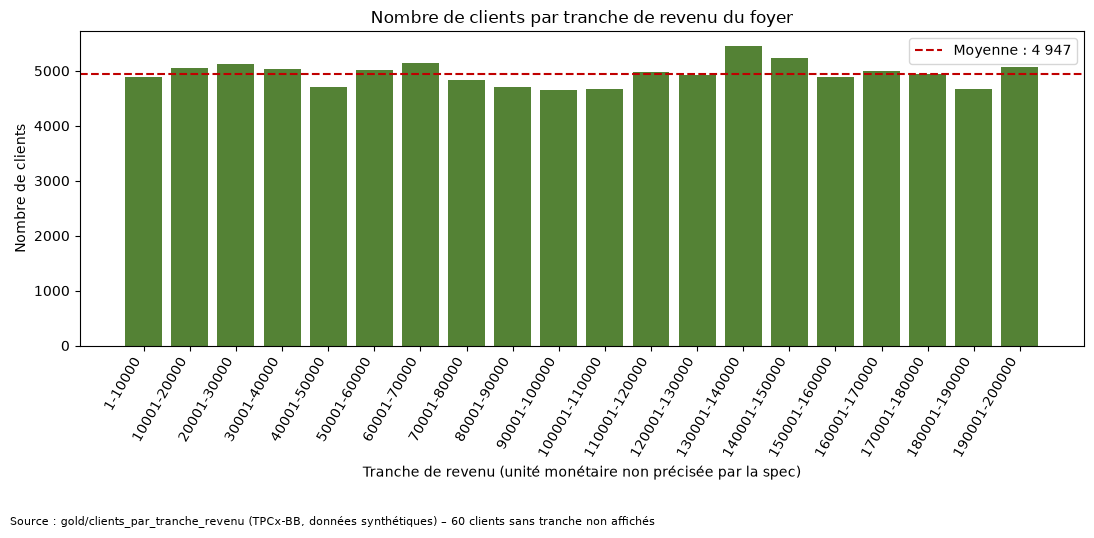

In [9]:
tr = g_tranche.filter(F.col('hd_income_band_sk').isNotNull()).orderBy('hd_income_band_sk').toPandas()
moy = tr['nb_clients'].mean()
print(tr[['tranche', 'nb_clients', 'part_pct']])
print('Moyenne par tranche :', round(moy, 1), '| écart min-max :', tr['nb_clients'].min(), '-', tr['nb_clients'].max(),
      '| rapport max/min :', round(tr['nb_clients'].max() / tr['nb_clients'].min(), 2))
tr.to_csv(OUT / 'clients_par_tranche_revenu.csv', index=False)

plt.figure(figsize=(11, 5))
plt.bar(tr['tranche'], tr['nb_clients'], color='#548235')
plt.axhline(moy, color='#C00000', linestyle='--', label=f'Moyenne : {moy:,.0f}'.replace(',', ' '))
plt.title('Nombre de clients par tranche de revenu du foyer')
plt.xlabel('Tranche de revenu (unité monétaire non précisée par la spec)')
plt.ylabel('Nombre de clients')
plt.xticks(rotation=60, ha='right')
plt.legend()
plt.figtext(0.01, -0.06, 'Source : gold/clients_par_tranche_revenu (TPCx-BB, données synthétiques) – 60 clients sans tranche non affichés', fontsize=8)
plt.tight_layout()
plt.savefig(VIS / 'clients_par_tranche_revenu.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Distribution de l'année de naissance des clients

Histogramme construit à partir d'un comptage par année calculé par Spark (une ligne par année).

69 années distinctes, 1924 -> 1992
Nombre de clients par année : min 1365 | max 1523 | moyenne 1434.3


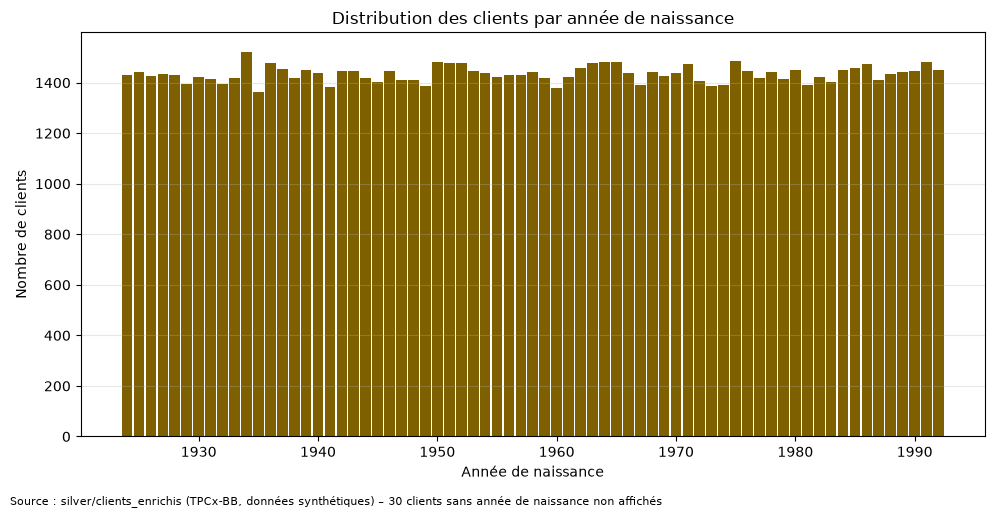

In [10]:
naiss = clients.filter(F.col('c_birth_year').isNotNull()).groupBy('c_birth_year').count().orderBy('c_birth_year').toPandas()
print(len(naiss), 'années distinctes,', naiss['c_birth_year'].min(), '->', naiss['c_birth_year'].max())
print('Nombre de clients par année : min', naiss['count'].min(), '| max', naiss['count'].max(), '| moyenne', round(naiss['count'].mean(), 1))
naiss.rename(columns={'count': 'nb_clients'}).to_csv(OUT / 'distribution_annee_naissance.csv', index=False)

plt.figure(figsize=(10, 5))
plt.bar(naiss['c_birth_year'], naiss['count'], width=0.9, color='#7F6000')
plt.title('Distribution des clients par année de naissance')
plt.xlabel('Année de naissance')
plt.ylabel('Nombre de clients')
plt.grid(True, axis='y', alpha=0.3)
plt.figtext(0.01, -0.02, 'Source : silver/clients_enrichis (TPCx-BB, données synthétiques) – 30 clients sans année de naissance non affichés', fontsize=8)
plt.tight_layout()
plt.savefig(VIS / 'distribution_annee_naissance.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Ce qui n'a pas pu être calculé

Les tables `store_sales`, `web_sales`, `store_returns`, `web_returns`, `item` et `store` ne sont pas dans le zip reçu : KPI-01 à KPI-07 ne sont pas calculables. Aucun graphique `ventes_par_magasin` ni `evolution_ventes_mensuelles` n'est produit. Les interprétations et les recommandations sont dans le rapport `UC08_analyse_visualisation.pdf`.